# Full Fisher matrix with jax backend

In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["JAX_COMPILATION_CACHE_DIR"] = "/home/nrui/.cache/jax"
os.environ["JAX_PERSISTENT_CACHE_MIN_COMPILE_TIME_SECS"] = "10"

import numpy as np
import pandas as pd
import jax
jax.config.update("jax_enable_x64", True)

import lal
import bilby

from pespace.detector.antenna import InterferometerAntenna, FDResponseModelMarset2018
from pespace.detector.tdi import TDIChannelData, FDMichelsonConstantEqualArm
from pespace.detector.orbit import KaplerianHeliocentric, KeplerianGeocentric
from pespace.inference.likelihood_jax import WhittleLikelihoodJax
from pespace.inference.fisher import (
    fisher_matrix,
    sample_from_fisher,
    wrap_angle_params,
)
from pespace.waveform.interface_ripple import IMRPhenomXAS
from pespace.waveform.interface_ripple import IMRPhenomXHM


/tmp/ipykernel_1255073/2682543860.py:11: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


[Taichi] version 1.7.4, llvm 15.0.4, commit b4b956fd, linux, python 3.12.14


[I 10/09/26 11:05:33.915 1255073] [shell.py:_shell_pop_print@23] Graphical python shell detected, using wrapped sys.stdout


In [2]:
tdi_gen = "2.0"
channels = ("A", "E", "T")

dt = 10
f_min = 1e-4
f_max = 0.5 * (1 / dt)
f_ref = f_min
t_start = 0.0

num_tsamples = 2 ** np.ceil(np.log2(7 * lal.DAYJUL_SI / dt))
duration = num_tsamples * dt
before_tc = 0.8 * duration
tc = t_start + before_tc

params = dict(
    total_mass=3e6,
    mass_ratio=0.6,
    chi_1=0.75,
    chi_2=0.62,
    luminosity_distance=56000.0,
    inclination=0.4,
    reference_phase=1.3,
    ecliptic_longitude=1.375,
    ecliptic_latitude=-1.2108,
    polarization=2.659,
    coalescence_time=tc,
)
params = bilby.gw.conversion.generate_mass_parameters(params)
params

{'total_mass': 3000000.0,
 'mass_ratio': 0.6,
 'chi_1': 0.75,
 'chi_2': 0.62,
 'luminosity_distance': 56000.0,
 'inclination': 0.4,
 'reference_phase': 1.3,
 'ecliptic_longitude': 1.375,
 'ecliptic_latitude': -1.2108,
 'polarization': 2.659,
 'coalescence_time': np.float64(524288.0),
 'mass_1': 1875000.0,
 'mass_2': 1125000.0,
 'chirp_mass': 1256226.717491785,
 'symmetric_mass_ratio': np.float64(0.234375)}

In [3]:
corner_parameters = [
    'chirp_mass',
    'mass_ratio',
    'chi_1',
    'chi_2',
    'luminosity_distance',
    'inclination',
    'reference_phase',
    'ecliptic_longitude',
    'ecliptic_latitude',
    'polarization',
    'coalescence_time',
]
latex_labels = {
    'chirp_mass':r"$\mathcal{M}$",
    'mass_ratio':r"$q$",
    'chi_1':r"$\chi_1$",
    'chi_2':r"$\chi_2$",
    'luminosity_distance':r"$d_L$",
    'inclination':r"$\iota$",
    'reference_phase':r"$\phi_{\mathrm{ref}}$",
    'ecliptic_longitude':r"$\lambda$",
    'ecliptic_latitude':r"$\beta$",
    'polarization':r"$\psi$",
    'coalescence_time':r"$t_c$",
}

In [4]:
pe_results= {
    'xas_lisa': ('../pe/outdir_inj_MBHB_LISA_noiseless', 'inj_MBHB_LISA_noiseless'),
    'xas_network': ('../pe/outdir_inj_MBHB_network_noiseless', 'inj_MBHB_network_noiseless'),
    'xhm_lisa': ('../pe/outdir_inj_MBHB_LISA_HM_noiseless_old', 'inj_MBHB_LISA_HM_noiseless'),
    'xhm_network': ('../pe/outdir_inj_MBHB_network_HM_noiseless', 'inj_MBHB_network_HM_noiseless'),
}

In [5]:
tdi_data = TDIChannelData(backend="jax")
tdi_data.set_fd_data_from_zero(
    channels=channels,
    duration=duration,
    delta_time=dt,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
)
tdi_data.set_fd_noise_power_density_from_model("LISA_SciRDv1", tdi_generation=tdi_gen)

lisa = InterferometerAntenna(
    name="lisa",
    tdi_data=tdi_data,
    orbit_model=KaplerianHeliocentric(2.5e9, 0.0, -np.pi / 9, backend="jax"),
    response_model=FDResponseModelMarset2018(backend="jax"),
    tdi_combination=FDMichelsonConstantEqualArm(
        generation=tdi_gen, orthogonal=True, backend="jax"
    ),
    backend="jax",
)

wf_xas = IMRPhenomXAS(tdi_data.frequency_samples, f_ref)
likelihood_xas_lisa = WhittleLikelihoodJax(waveform=wf_xas, detector=lisa, channels=channels)

In [6]:
# fiducial parameters as a dict, ordered as likelihood_xas_lisa.likelihood_param_type
fiducial_xas_lisa = {
    name: params[name] for name in likelihood_xas_lisa.likelihood_param_type._fields
}
fisher_xas_lisa = fisher_matrix(likelihood_xas_lisa, fiducial_xas_lisa)

theta0_xas_lisa = np.array(list(fiducial_xas_lisa.values()))
num_samples = 100_000
draws_xas_lisa = theta0_xas_lisa + sample_from_fisher(fisher_xas_lisa, num_samples, rkey_seed=2026)
samples_xas_lisa = {name: draws_xas_lisa[:, i] for i, name in enumerate(fiducial_xas_lisa)}
samples_xas_lisa = wrap_angle_params(samples_xas_lisa)

samples_xas_lisa = {name: np.asarray(values) for name, values in samples_xas_lisa.items()}
samples_xas_lisa['mass_ratio'] = bilby.gw.conversion.symmetric_mass_ratio_to_mass_ratio(samples_xas_lisa["symmetric_mass_ratio"])
samples_xas_lisa = pd.DataFrame(samples_xas_lisa)


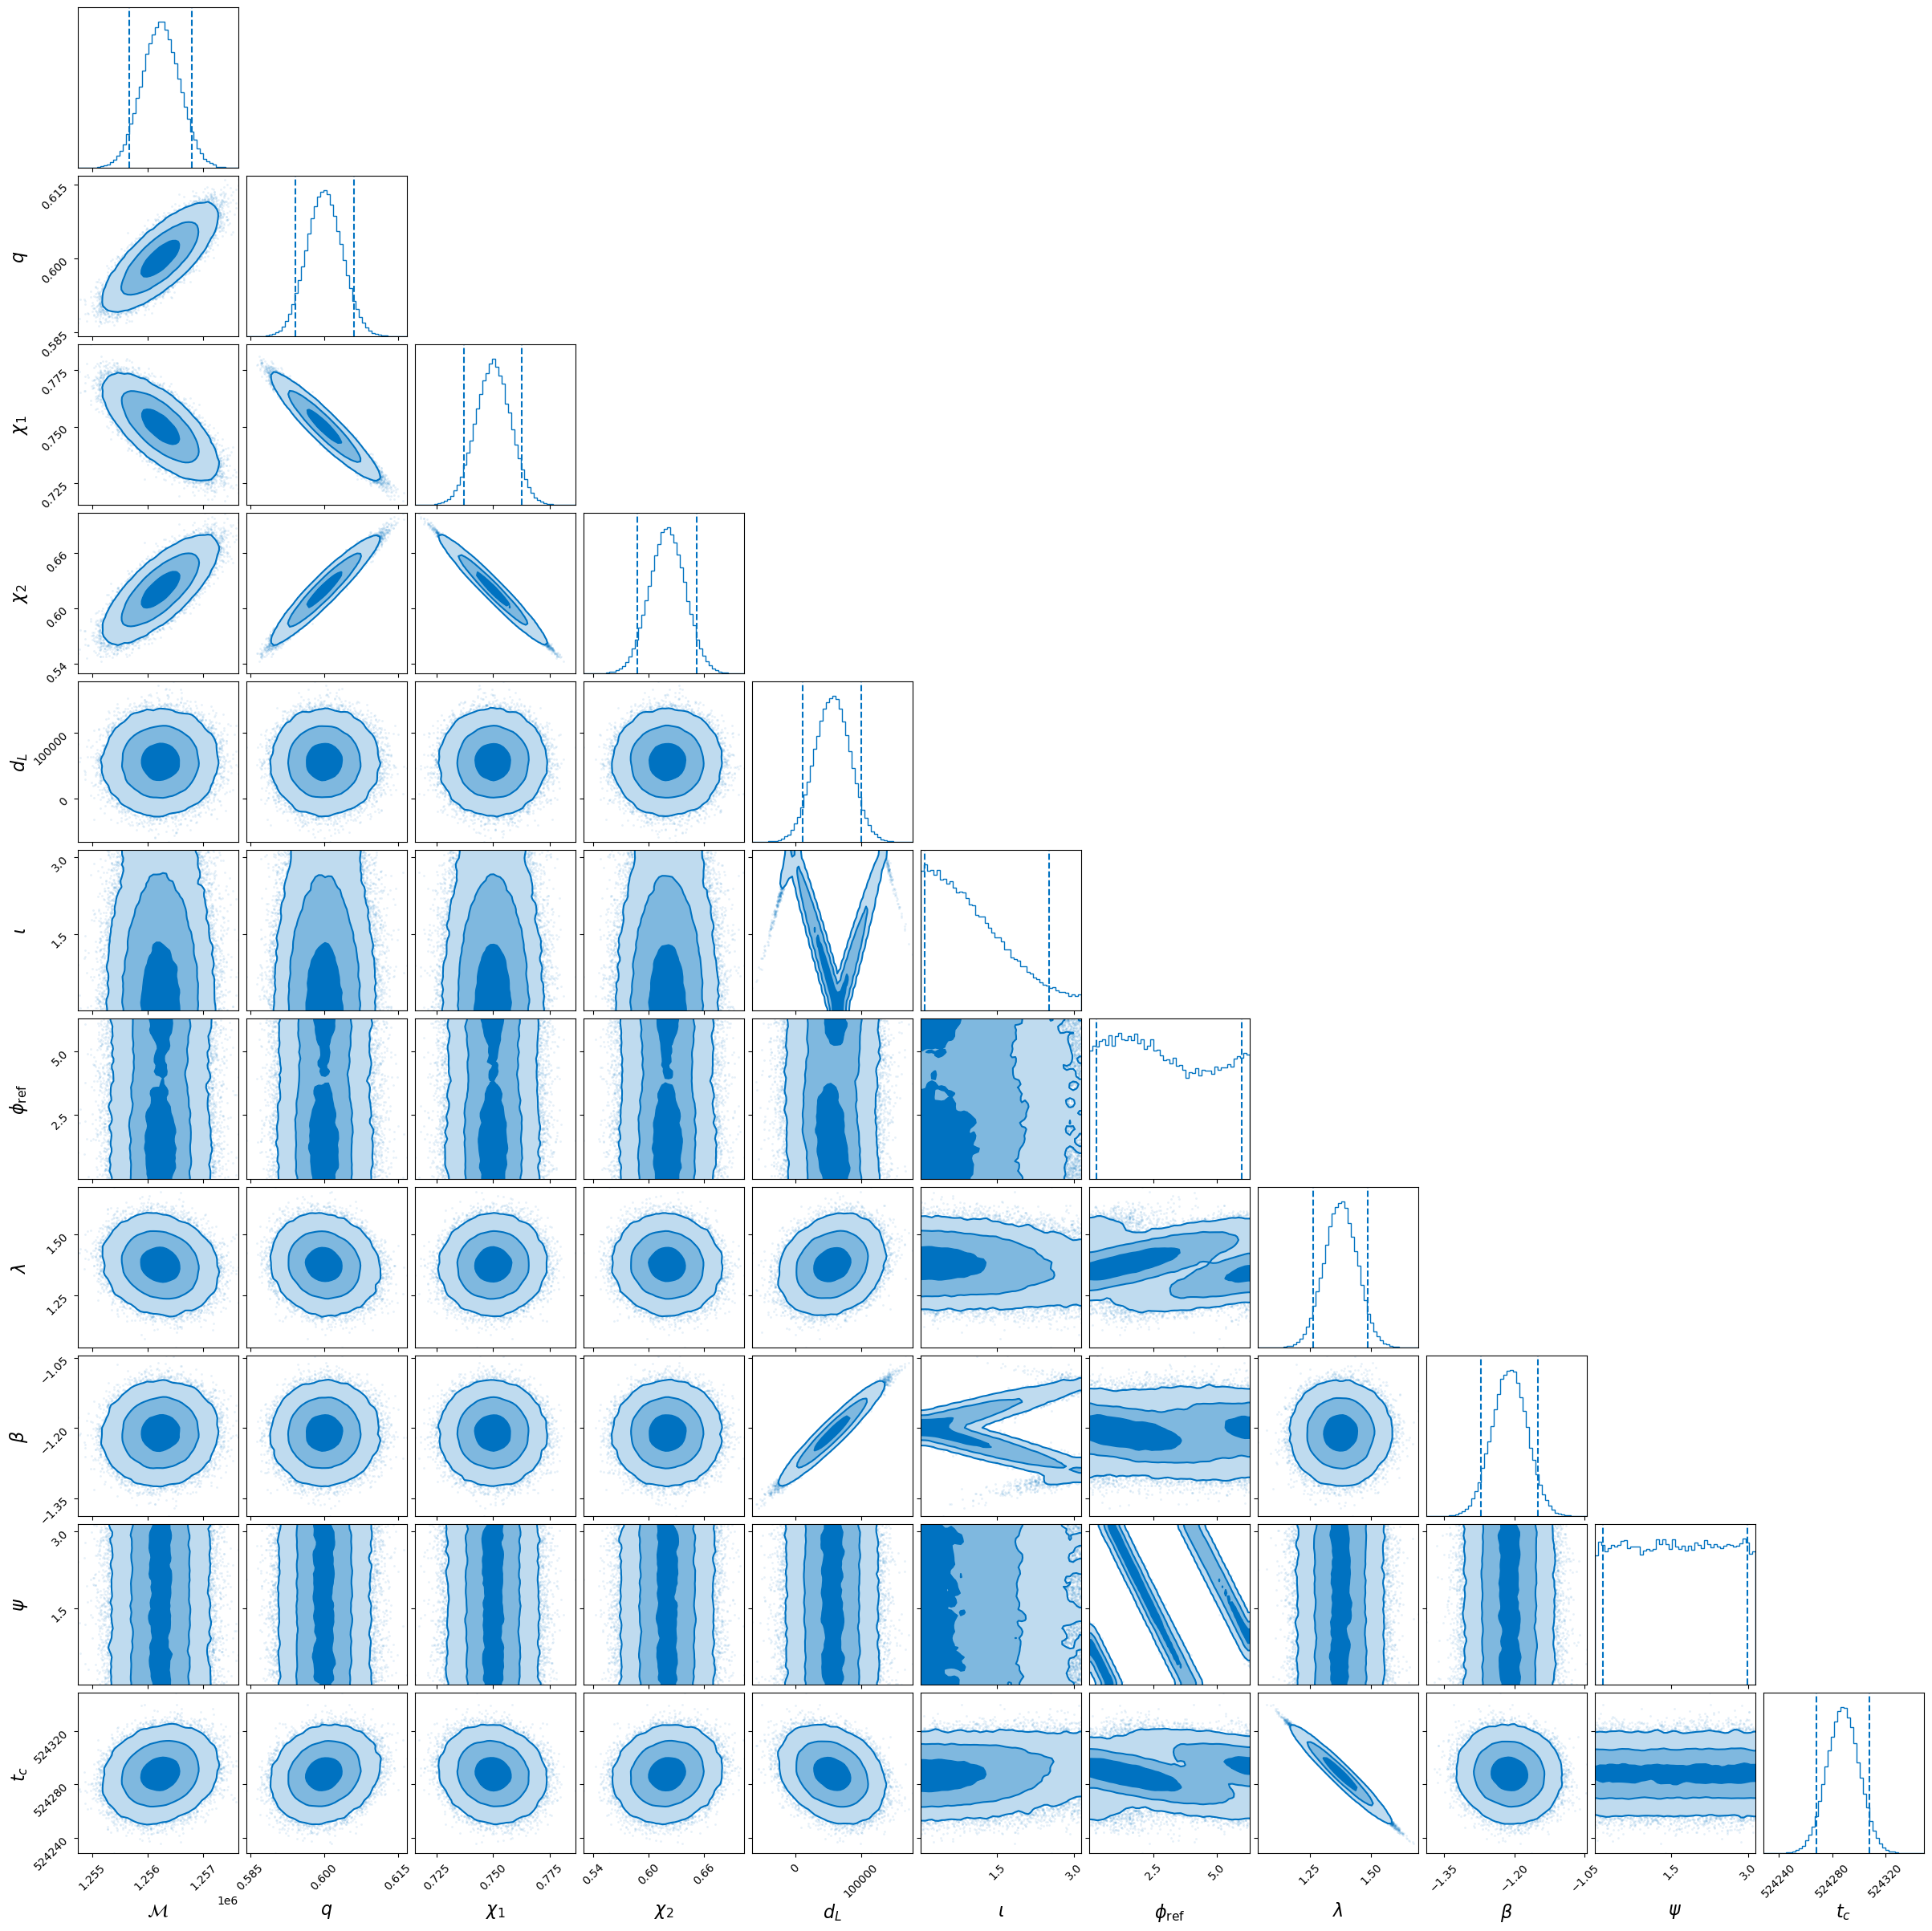

In [7]:
res_fisher_xas_lisa = bilby.core.result.Result(
    label="fisher_xas_lisa",
    search_parameter_keys=corner_parameters,
    posterior=samples_xas_lisa,
)
fig_xas_lisa = res_fisher_xas_lisa.plot_corner(
    parameters=corner_parameters,
    labels=[latex_labels[name] for name in corner_parameters],
    save=False,
    titles=False,
    quantiles=[0.05, 0.95],
)

In [8]:
import os
os.environ['PATH'] = "/home/nrui/.local/texlive/2025/bin/x86_64-linux:" + os.environ['PATH']

import matplotlib 
plot_params = {
    'axes.labelsize': 20,
    'font.family': 'serif',
    'font.serif': 'Computer Modern',
    # 'font.size': 24,
    'legend.fontsize': 40,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    # 'axes.grid' : False,
    'text.usetex': True,
    # 'savefig.dpi' : 100,
    # 'lines.markersize' : 14,
    }
matplotlib.rcParams.update(plot_params)


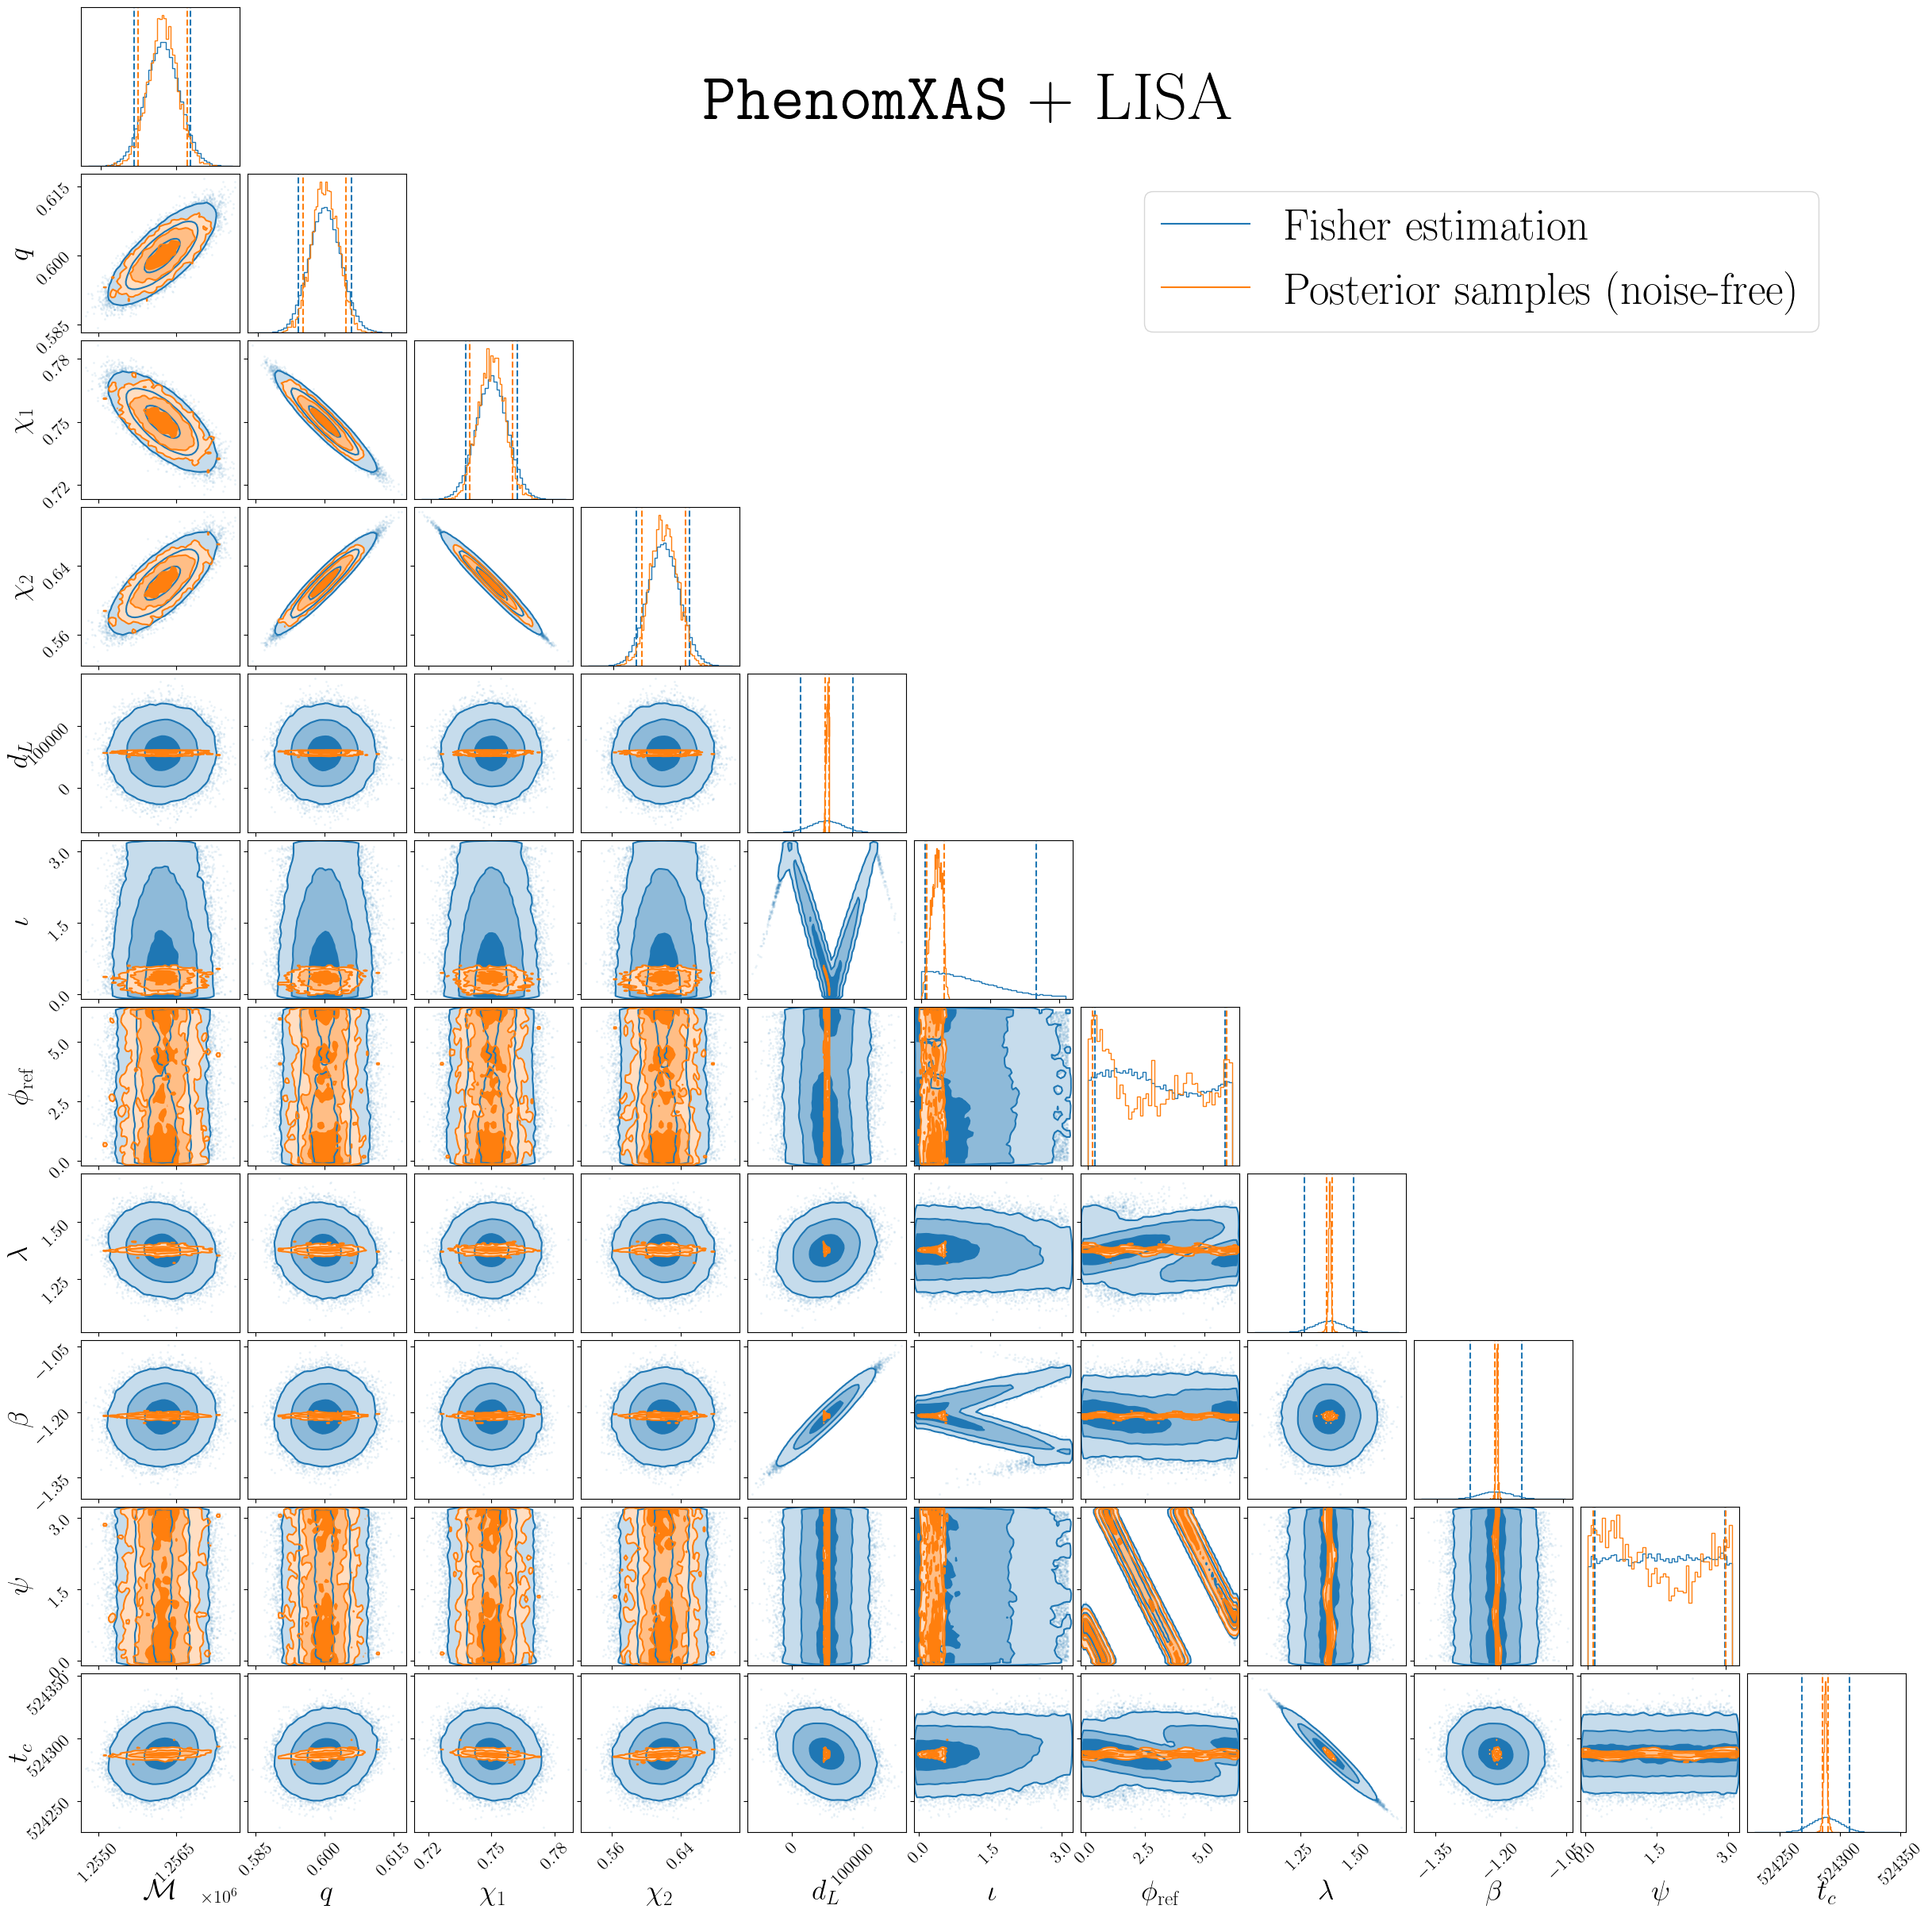

In [9]:
res_pe_xas_lisa = bilby.core.result.read_in_result(outdir=pe_results['xas_lisa'][0], label=pe_results['xas_lisa'][1])
fig_cmp_xas_lisa = bilby.core.result.plot_multiple(
    [res_fisher_xas_lisa, res_pe_xas_lisa],
    filename='corner_fisher_xas_lisa.pdf',
    labels=["Fisher estimation", "Posterior samples (noise-free)"],
    titles=False,
    parameters=corner_parameters,
    save=False,
    quantiles=[0.05, 0.95],
    corner_labels=[latex_labels[name] for name in corner_parameters],
    label_kwargs={'fontsize': 26},
)

leg = fig_cmp_xas_lisa.axes[10].get_legend()
leg.set_loc("upper right")
leg.set_bbox_to_anchor((0.95, 0.9), transform=fig_cmp_xas_lisa.transFigure)

fig_cmp_xas_lisa.suptitle(r"\texttt{PhenomXAS} + LISA", fontsize=60, y=0.95)
fig_cmp_xas_lisa.savefig('corner_fisher_xas_lisa.pdf')

## IMRPhenomXHM + LISA

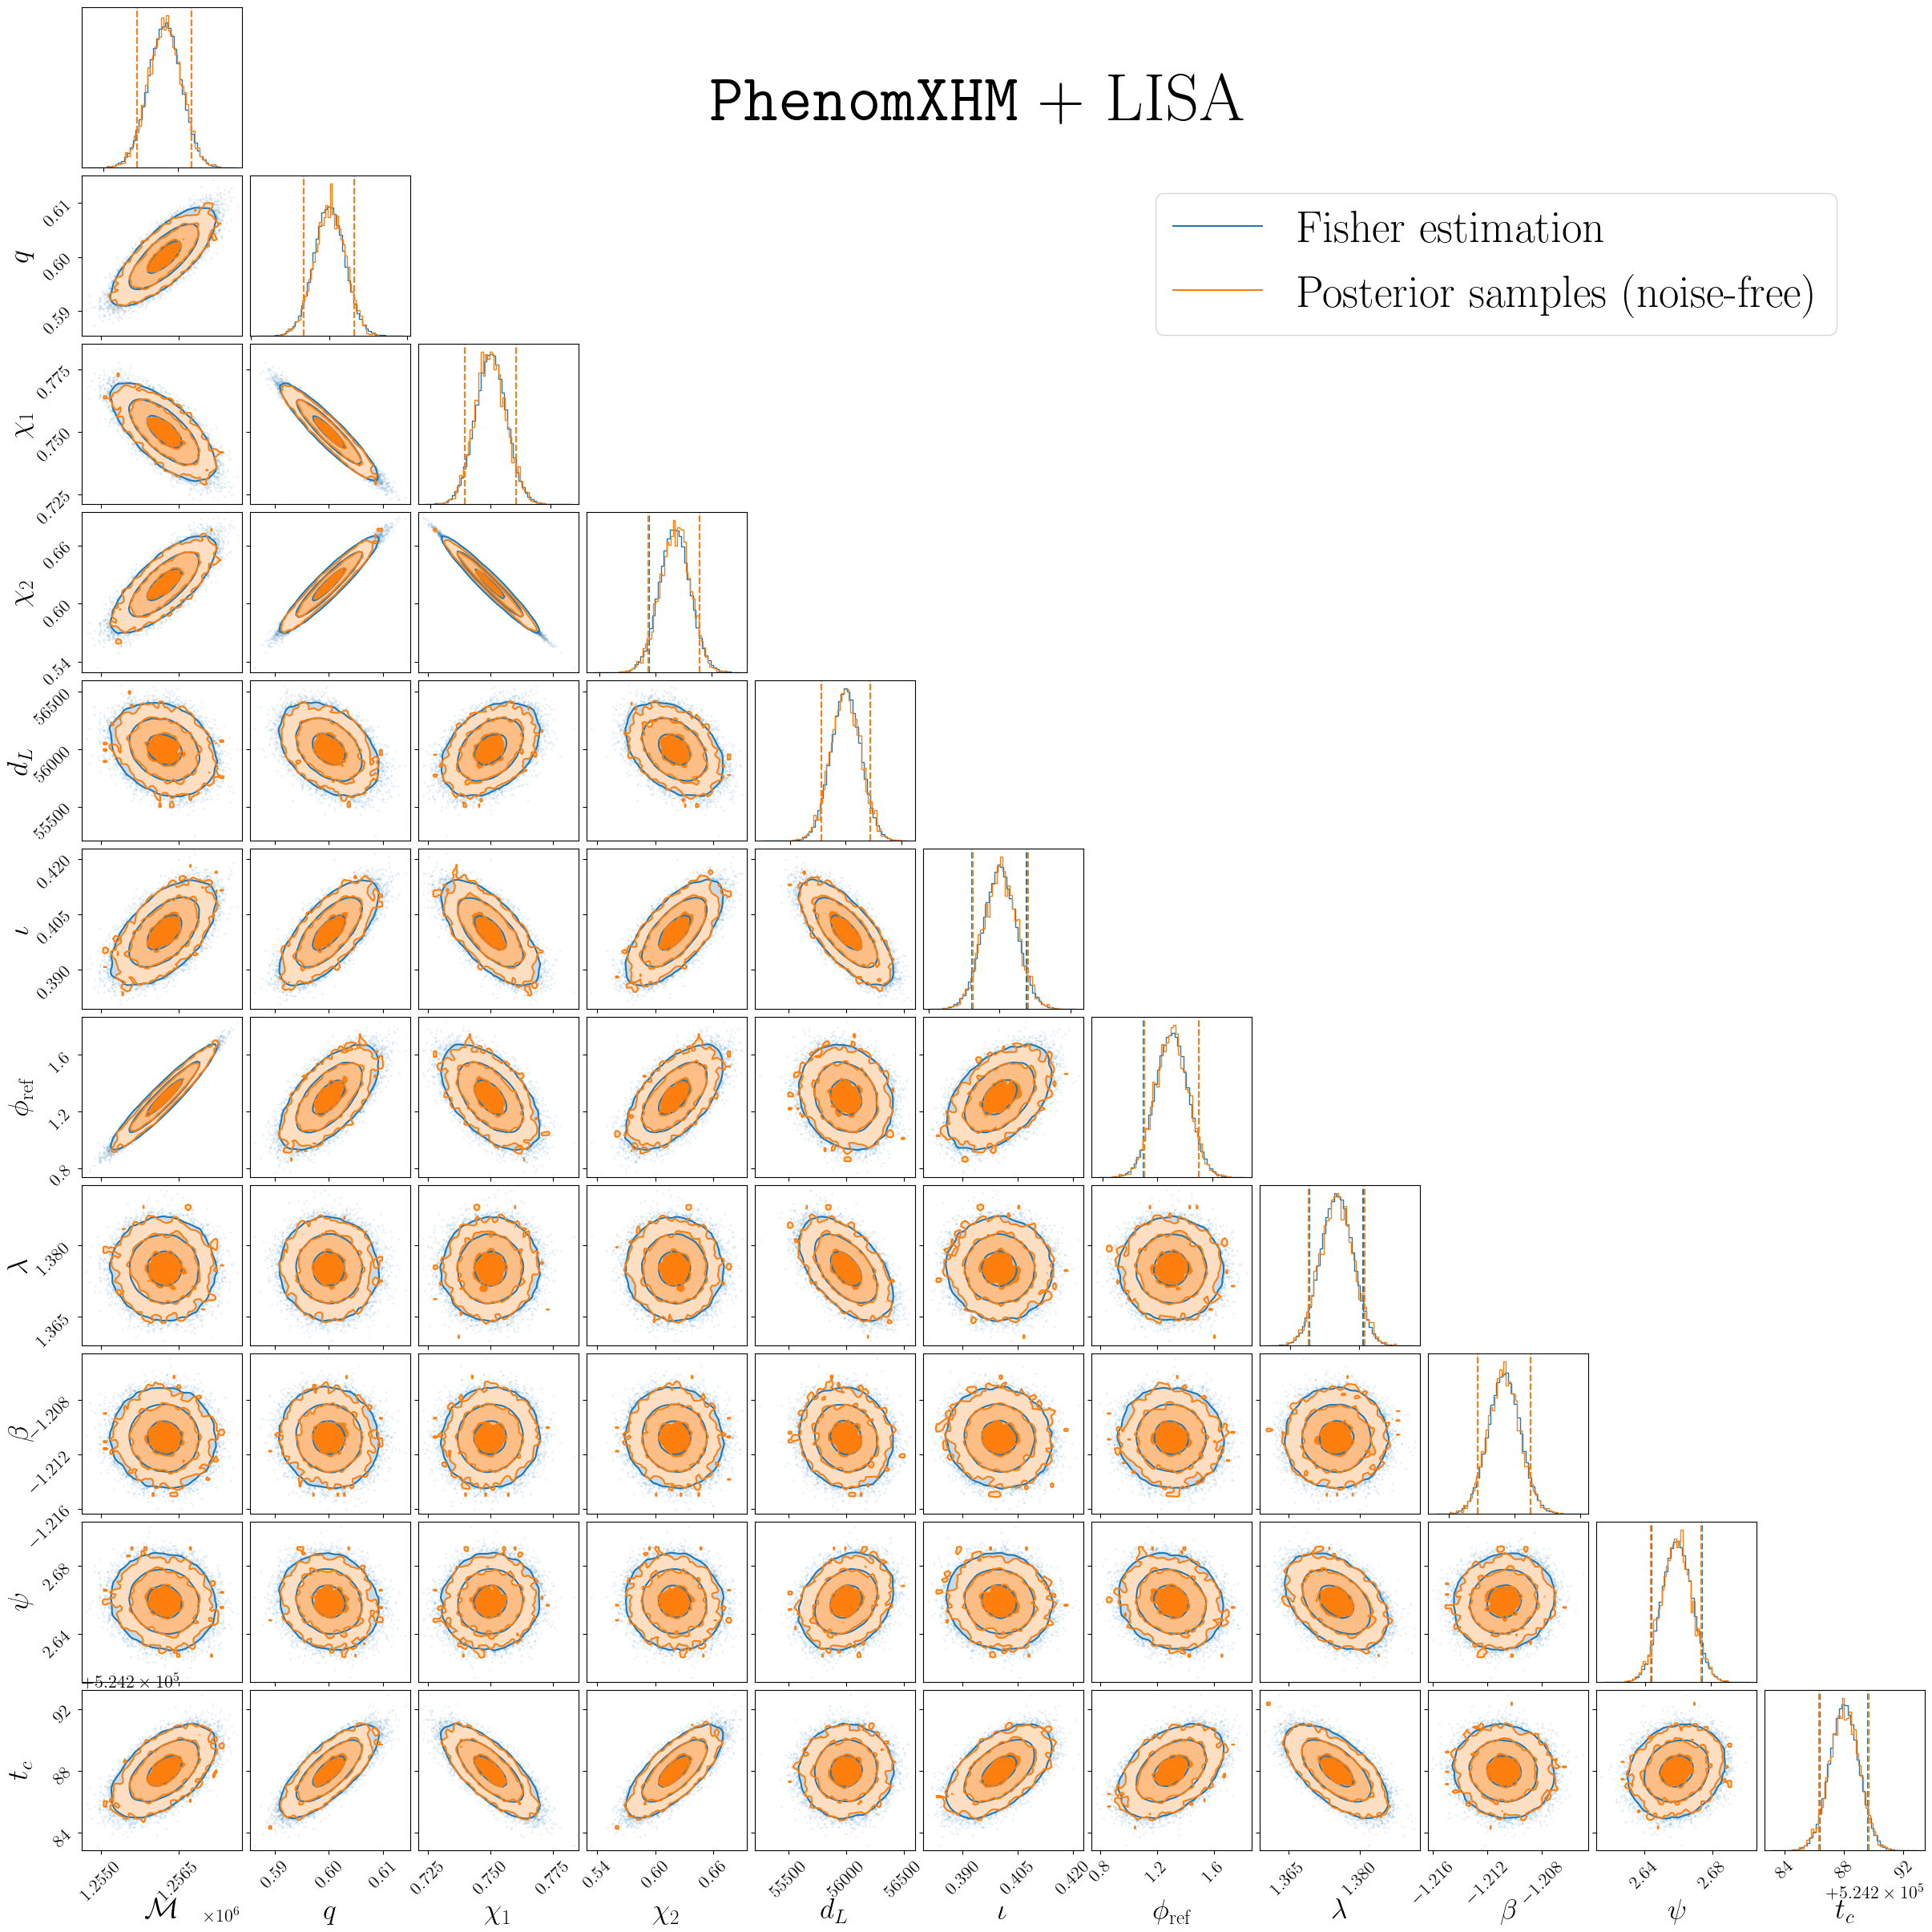

In [10]:
wf_xhm = IMRPhenomXHM(tdi_data.frequency_samples, f_ref)
likelihood_xhm_lisa = WhittleLikelihoodJax(waveform=wf_xhm, detector=lisa, channels=channels)
fiducial_xhm_lisa = {
    name: params[name] for name in likelihood_xhm_lisa.likelihood_param_type._fields
}
fisher_xhm_lisa = np.asarray(fisher_matrix(likelihood_xhm_lisa, fiducial_xhm_lisa))

theta0_xhm_lisa = np.array(list(fiducial_xhm_lisa.values()))
draws_xhm_lisa = theta0_xhm_lisa + sample_from_fisher(fisher_xhm_lisa, num_samples, rkey_seed=2026)
samples_xhm_lisa = {name: draws_xhm_lisa[:, i] for i, name in enumerate(fiducial_xhm_lisa)}
samples_xhm_lisa = wrap_angle_params(samples_xhm_lisa)
samples_xhm_lisa = {name: np.asarray(values) for name, values in samples_xhm_lisa.items()}

samples_xhm_lisa['chirp_mass'] = bilby.gw.conversion.component_masses_to_chirp_mass(
    samples_xhm_lisa["mass_1"], samples_xhm_lisa["mass_2"]
)
samples_xhm_lisa['mass_ratio'] = bilby.gw.conversion.component_masses_to_mass_ratio(
    samples_xhm_lisa["mass_1"], samples_xhm_lisa["mass_2"]
)

res_fisher_xhm_lisa = bilby.core.result.Result(
    label="fisher_xhm_lisa",
    search_parameter_keys=corner_parameters,
    posterior=pd.DataFrame(samples_xhm_lisa),
)

res_pe_xhm_lisa = bilby.core.result.read_in_result(outdir=pe_results['xhm_lisa'][0], label=pe_results['xhm_lisa'][1])
fig_cmp_xhm_lisa = bilby.core.result.plot_multiple(
    [res_fisher_xhm_lisa, res_pe_xhm_lisa],
    filename='corner_fisher_xhm_lisa.pdf',
    labels=["Fisher estimation", "Posterior samples (noise-free)"],
    titles=False,
    parameters=corner_parameters,
    save=False,
    quantiles=[0.05, 0.95],
    corner_labels=[latex_labels[name] for name in corner_parameters],
    label_kwargs={'fontsize': 26},
)

leg = fig_cmp_xhm_lisa.axes[10].get_legend()
leg.set_loc("upper right")
leg.set_bbox_to_anchor((0.95, 0.9), transform=fig_cmp_xhm_lisa.transFigure)

fig_cmp_xhm_lisa.suptitle(r"\texttt{PhenomXHM} + LISA", fontsize=60, y=0.95)
fig_cmp_xhm_lisa.savefig('corner_fisher_xhm_lisa.pdf')

## IMRPhenomXHM + Network

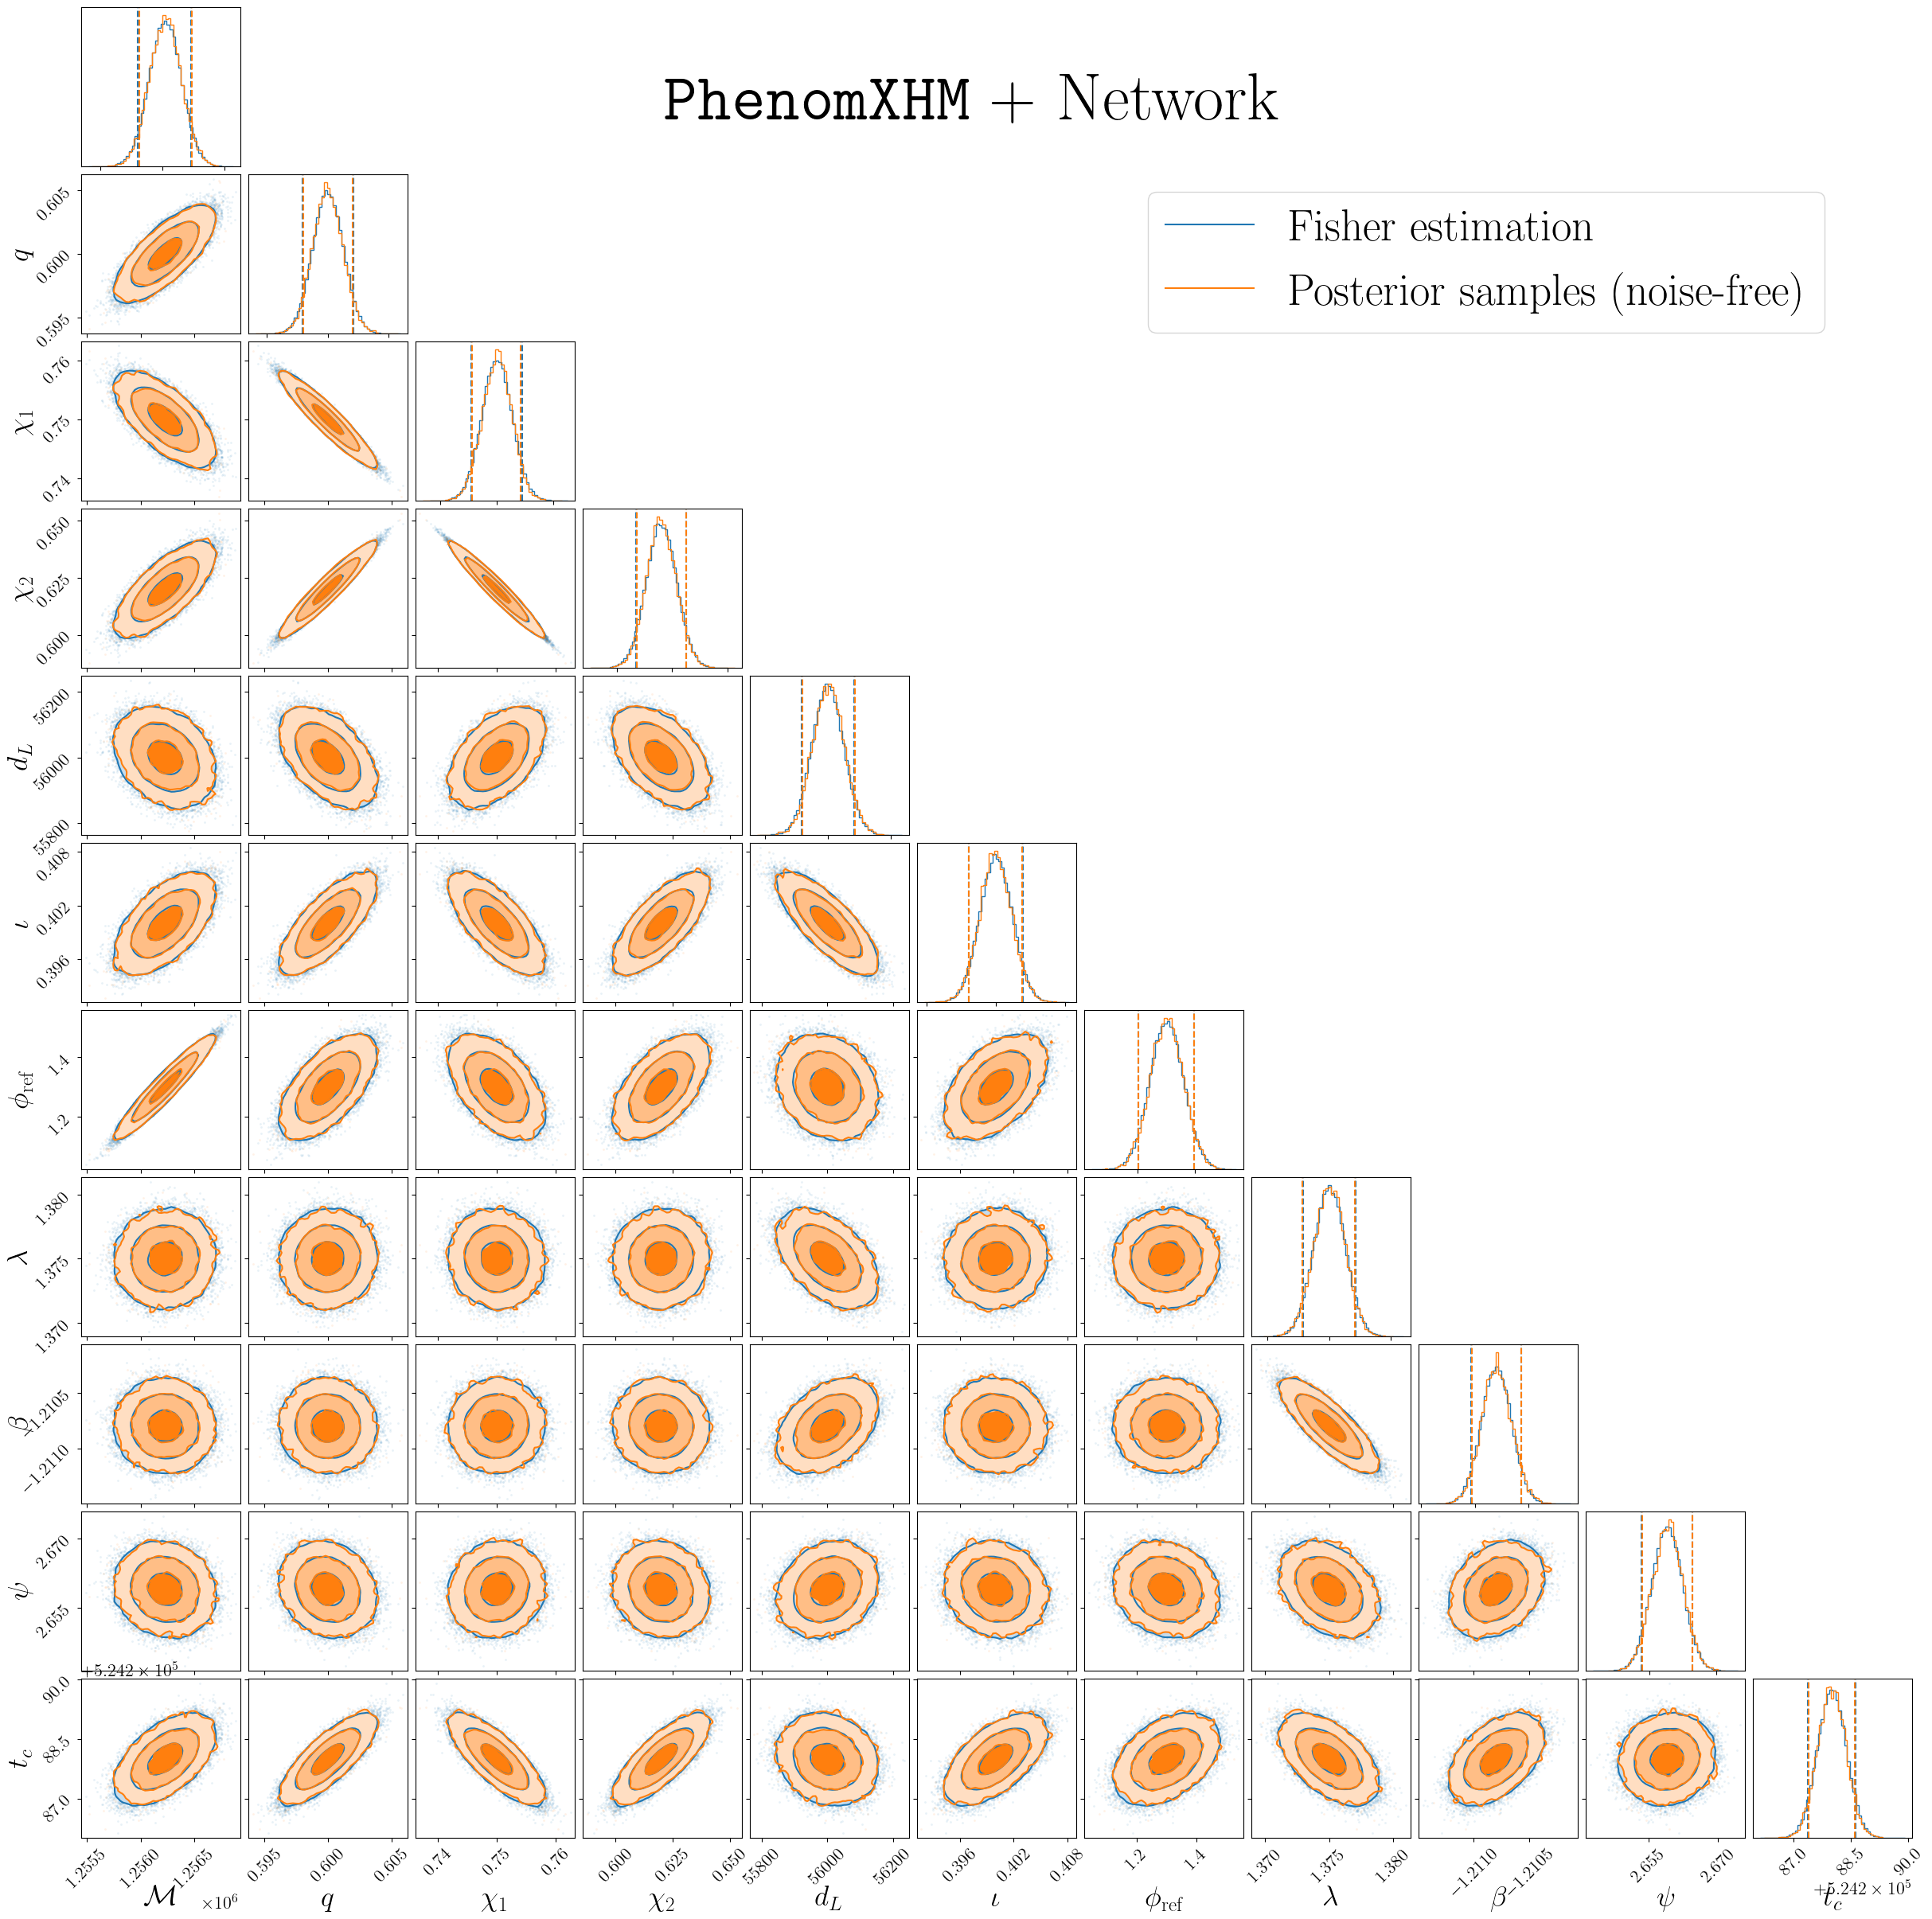

In [11]:
det_models = {
    "lisa": ("LISA_SciRDv1", KaplerianHeliocentric(2.5e9, 0.0, -np.pi / 9, backend="jax")),
    "taiji": ("Taiji_TDC", KaplerianHeliocentric(3.0e9, 0.0, np.pi / 9, backend="jax")),
    "tianqin": ("Tianqin_GWSpace", KeplerianGeocentric(1.7e8, 0.0, 0.0, backend="jax")),
}
det_net = []
for name, (psd_model, orbit_model) in det_models.items():
    tdi_data_det = TDIChannelData(backend="jax")
    tdi_data_det.set_fd_data_from_zero(
        channels=channels,
        duration=duration,
        delta_time=dt,
        start_time=t_start,
        minimum_frequency=f_min,
        maximum_frequency=f_max,
    )
    tdi_data_det.set_fd_noise_power_density_from_model(psd_model, tdi_generation=tdi_gen)
    det_net.append(
        InterferometerAntenna(
            name=name,
            tdi_data=tdi_data_det,
            orbit_model=orbit_model,
            response_model=FDResponseModelMarset2018(backend="jax"),
            tdi_combination=FDMichelsonConstantEqualArm(
                generation=tdi_gen, orthogonal=True, backend="jax"
            ),
            backend="jax",
        )
    )

likelihood_xhm_net = WhittleLikelihoodJax(
    waveform=wf_xhm, detector=tuple(det_net), channels=channels
)
fiducial_xhm_net = {
    name: params[name] for name in likelihood_xhm_net.likelihood_param_type._fields
}
fisher_xhm_net = np.asarray(fisher_matrix(likelihood_xhm_net, fiducial_xhm_net))

theta0_xhm_net = np.array(list(fiducial_xhm_net.values()))
draws_xhm_net = theta0_xhm_net + sample_from_fisher(fisher_xhm_net, num_samples, rkey_seed=2026)
samples_xhm_net = {name: draws_xhm_net[:, i] for i, name in enumerate(fiducial_xhm_net)}
samples_xhm_net = wrap_angle_params(samples_xhm_net)
samples_xhm_net = {name: np.asarray(values) for name, values in samples_xhm_net.items()}

samples_xhm_net['chirp_mass'] = bilby.gw.conversion.component_masses_to_chirp_mass(
    samples_xhm_net["mass_1"], samples_xhm_net["mass_2"]
)
samples_xhm_net['mass_ratio'] = bilby.gw.conversion.component_masses_to_mass_ratio(
    samples_xhm_net["mass_1"], samples_xhm_net["mass_2"]
)

res_fisher_xhm_net = bilby.core.result.Result(
    label="fisher_xhm_network",
    search_parameter_keys=corner_parameters,
    posterior=pd.DataFrame(samples_xhm_net),
)

res_pe_xhm_net = bilby.core.result.read_in_result(outdir=pe_results['xhm_network'][0], label=pe_results['xhm_network'][1])
fig_cmp_xhm_net = bilby.core.result.plot_multiple(
    [res_fisher_xhm_net, res_pe_xhm_net],
    filename='corner_fisher_xhm_network.pdf',
    labels=["Fisher estimation", "Posterior samples (noise-free)"],
    titles=False,
    parameters=corner_parameters,
    save=False,
    quantiles=[0.05, 0.95],
    corner_labels=[latex_labels[name] for name in corner_parameters],
    label_kwargs={'fontsize': 26},
)

leg = fig_cmp_xhm_net.axes[10].get_legend()
leg.set_loc("upper right")
leg.set_bbox_to_anchor((0.95, 0.9), transform=fig_cmp_xhm_net.transFigure)

fig_cmp_xhm_net.suptitle(r"\texttt{PhenomXHM} + Network", fontsize=60, y=0.95)
fig_cmp_xhm_net.savefig('corner_fisher_xhm_network.pdf')


## IMRPhenomXAS + Network

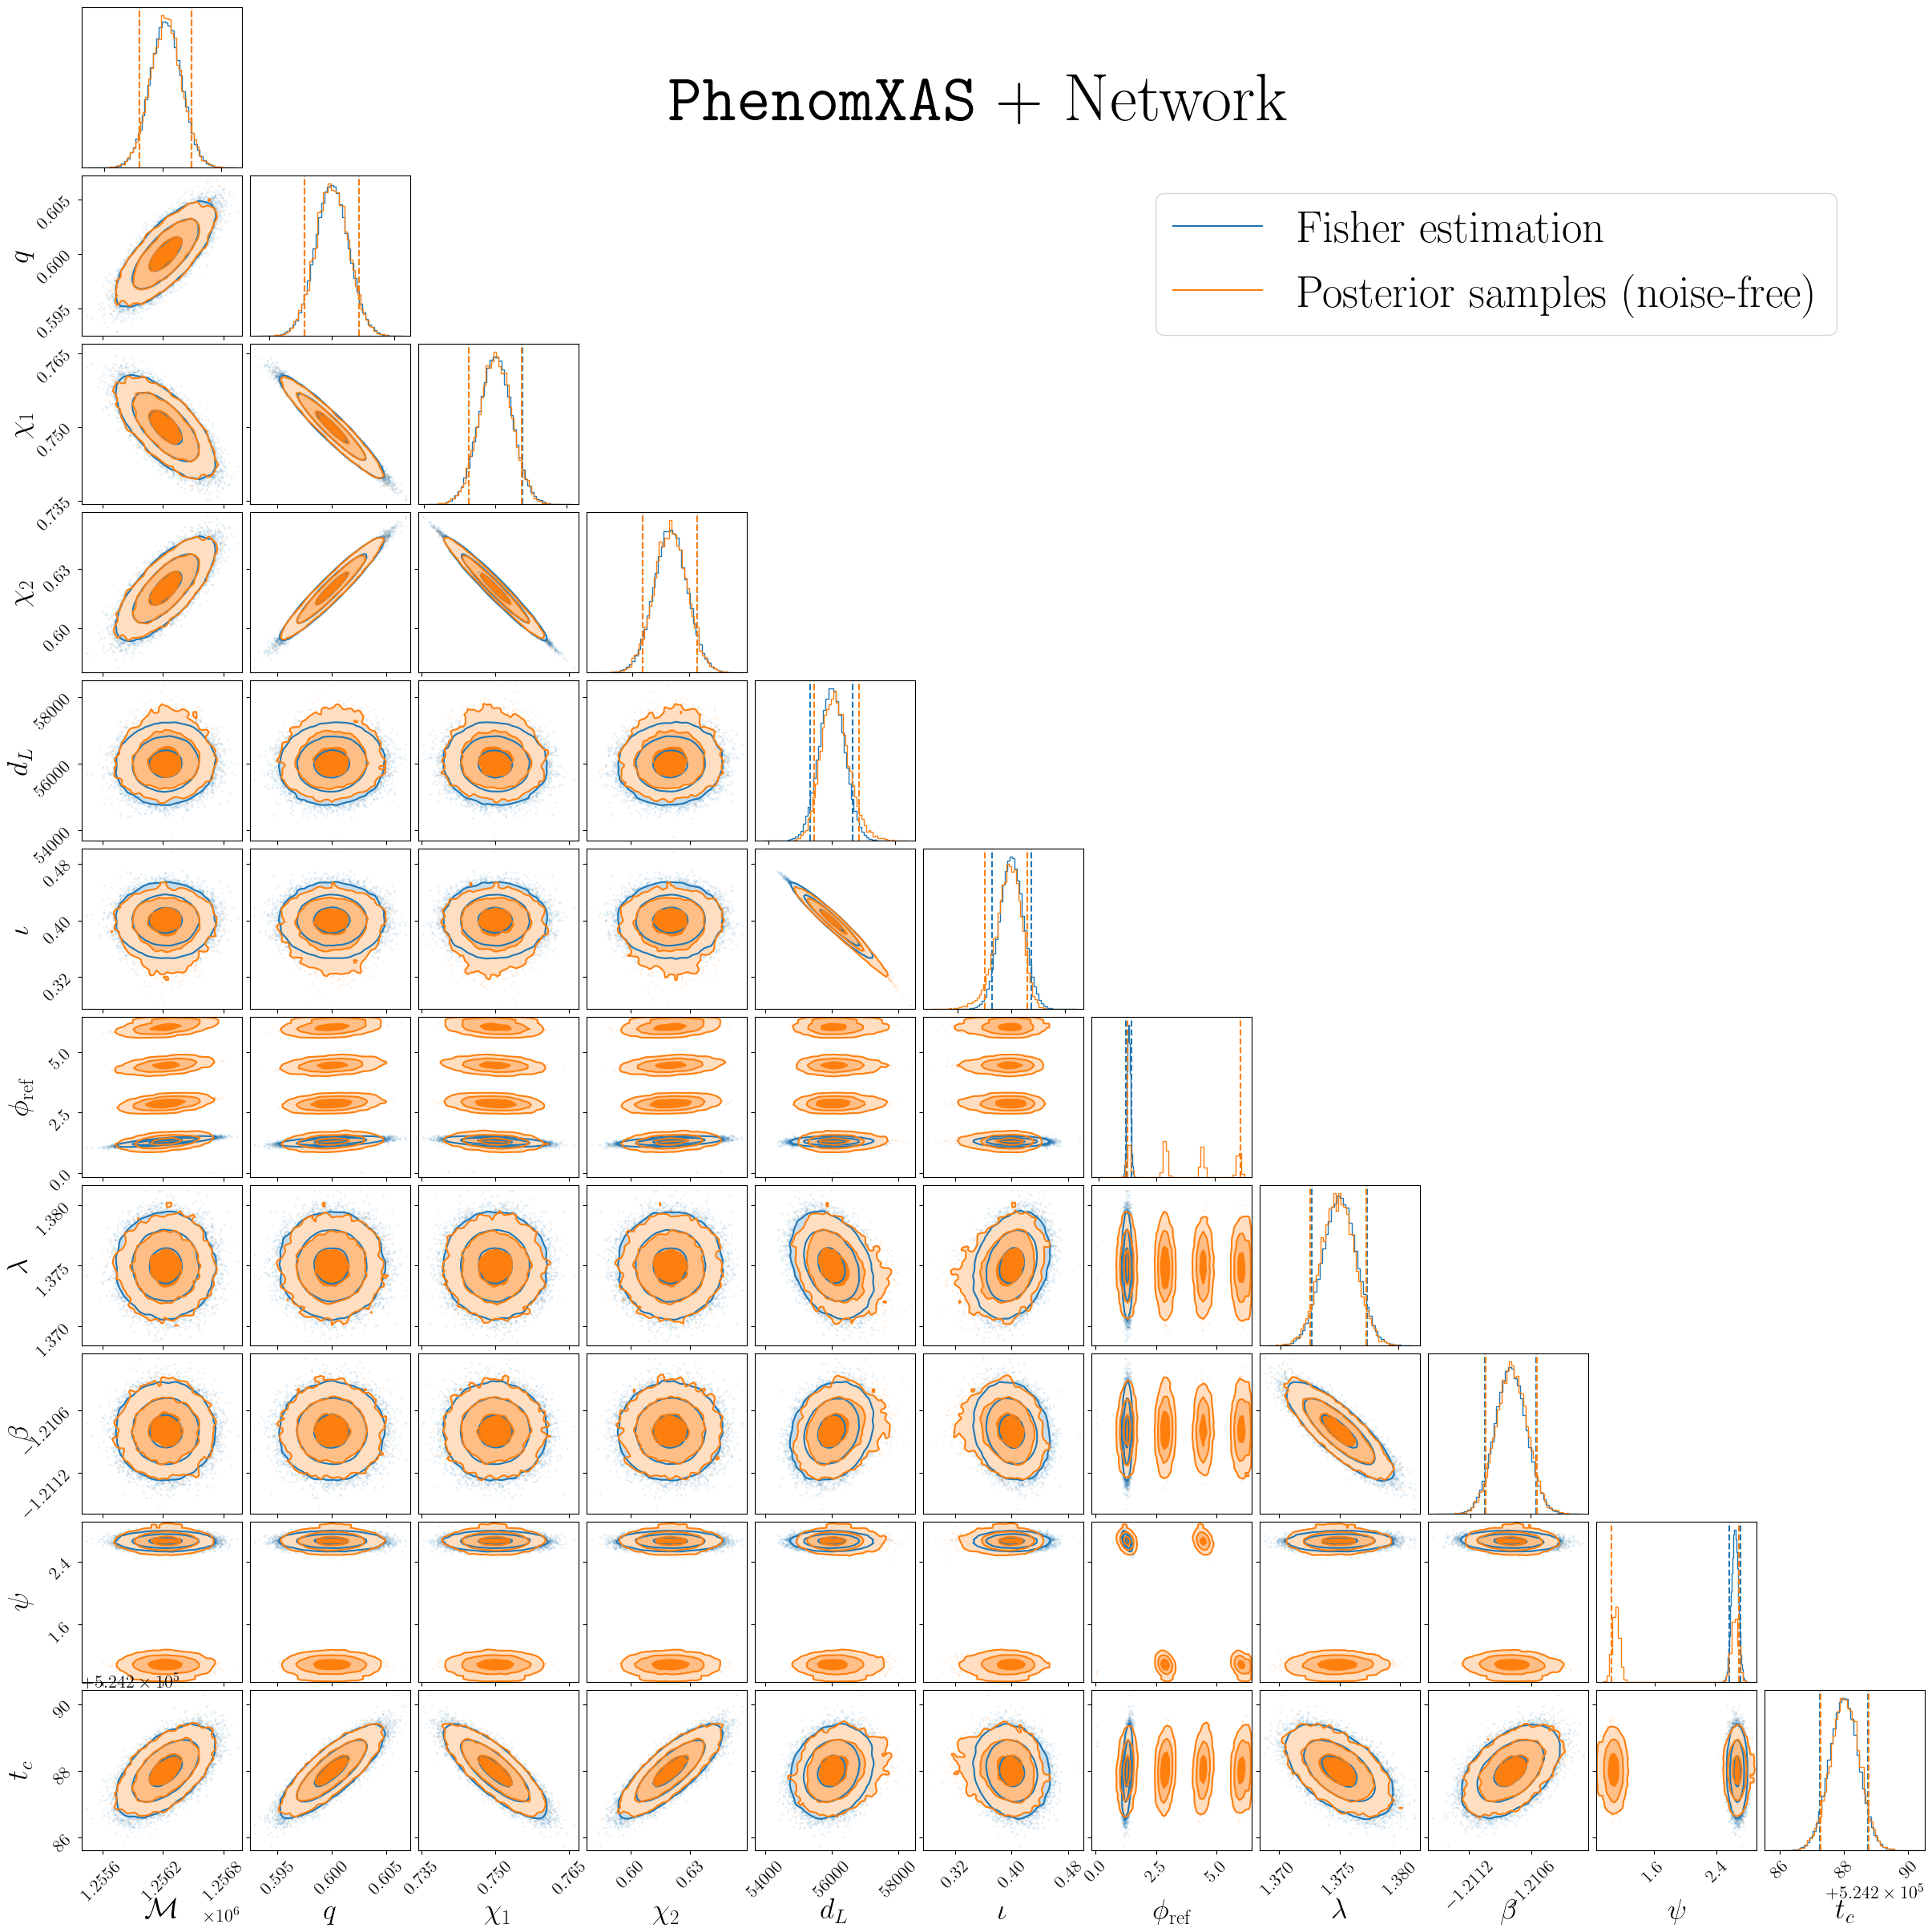

In [12]:
likelihood_xas_net = WhittleLikelihoodJax(
    waveform=wf_xas, detector=tuple(det_net), channels=channels
)
fiducial_xas_net = {
    name: params[name] for name in likelihood_xas_net.likelihood_param_type._fields
}
fisher_xas_net = np.asarray(fisher_matrix(likelihood_xas_net, fiducial_xas_net))

theta0_xas_net = np.array(list(fiducial_xas_net.values()))
draws_xas_net = theta0_xas_net + sample_from_fisher(fisher_xas_net, num_samples, rkey_seed=2026)
samples_xas_net = {name: draws_xas_net[:, i] for i, name in enumerate(fiducial_xas_net)}
samples_xas_net = wrap_angle_params(samples_xas_net)
samples_xas_net = {name: np.asarray(values) for name, values in samples_xas_net.items()}

samples_xas_net['mass_ratio'] = bilby.gw.conversion.symmetric_mass_ratio_to_mass_ratio(
    samples_xas_net["symmetric_mass_ratio"]
)

res_fisher_xas_net = bilby.core.result.Result(
    label="fisher_xas_network",
    search_parameter_keys=corner_parameters,
    posterior=pd.DataFrame(samples_xas_net),
)

res_pe_xas_net = bilby.core.result.read_in_result(outdir=pe_results['xas_network'][0], label=pe_results['xas_network'][1])
fig_cmp_xas_net = bilby.core.result.plot_multiple(
    [res_fisher_xas_net, res_pe_xas_net],
    filename='corner_fisher_xas_network.pdf',
    labels=["Fisher estimation", "Posterior samples (noise-free)"],
    titles=False,
    parameters=corner_parameters,
    save=False,
    quantiles=[0.05, 0.95],
    corner_labels=[latex_labels[name] for name in corner_parameters],
    label_kwargs={'fontsize': 26},
)

leg = fig_cmp_xas_net.axes[10].get_legend()
leg.set_loc("upper right")
leg.set_bbox_to_anchor((0.95, 0.9), transform=fig_cmp_xas_net.transFigure)

fig_cmp_xas_net.suptitle(r"\texttt{PhenomXAS} + Network", fontsize=60, y=0.95)
fig_cmp_xas_net.savefig('corner_fisher_xas_network.pdf')